In [107]:
import pandas as pd
import numpy as np
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.model_selection import LeaveOneGroupOut, cross_val_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from collections import Counter
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from sklearn.feature_selection import SequentialFeatureSelector
import matplotlib.pyplot as plt

Keep only labels for stress and neutral

In [108]:
features = pd.read_csv("../Data/wesad_eda/feature_dataframe.csv")
neutral = features[features['label'] == 1]
amusement = features[features['label'] == 3]
stress = features[features['label'] == 2]
#feature_binary = pd.concat([neutral, stress, amusement])
feature_binary = pd.concat([neutral, stress])

feature_binary.columns

Index(['label', 'subject_id', 'eda_mean', 'eda_max', 'eda_std', 'eda_skew',
       'eda_norm1', 'eda_median', 'eda_min', 'eda_range', 'eda_mean_slope',
       'eda_kurtosis', 'eda_sampen', 'eda_apen', 'phasic_mean', 'phasic_max',
       'phasic_std', 'phasic_skew', 'phasic_norm1', 'phasic_median',
       'phasic_min', 'phasic_range', 'phasic_mean_slope', 'phasic_kurtosis',
       'phasic_sampen', 'phasic_apen', 'phasic_peak_count', 'phasic_peak_rate',
       'phasic_mean_amplitude', 'phasic_max_amplitude', 'phasic_sum_amplitude',
       'phasic_mean_rise_time', 'phasic_std_rise_time',
       'phasic_mean_recovery_time', 'phasic_mean_onset_time',
       'phasic_mean_offset_time', 'phasic_shape_symmetry', 'eda_symp_power',
       'tonic_mean', 'tonic_max', 'tonic_std', 'tonic_skew', 'tonic_norm1',
       'tonic_median', 'tonic_min', 'tonic_range', 'tonic_mean_slope',
       'tonic_kurtosis', 'tonic_sampen', 'tonic_apen'],
      dtype='str')

Apply feature wise per subject normalization

In [109]:
feature_binary = feature_binary.drop(columns=['eda_symp_power'])
feature_cols = feature_binary.columns.drop(['label', 'subject_id'])
feature_binary = feature_binary.dropna()
def minmax_per_subject(group):
    return (group - group.min()) / (group.max() - group.min())
feature_max = feature_binary.copy()
feature_max[feature_cols] = (
    feature_max
    .groupby('subject_id')[feature_cols]
    .transform(minmax_per_subject)
)

Different Normalization of the feature sets
- X is max normalization
- Xn is ranked based normalization
- Xb is normalized against baseline
- xrkb is simply the ranked and baseline features together, through testing I found together they make up for shortcomings in each other multiclass classification

In [110]:
#By default X will be max normalizied following the inital paper design
groups = feature_binary['subject_id']
y = feature_max[['label']].values.ravel()
X = feature_max.iloc[:, 2:]


feats = [c for c in feature_binary.columns if c not in ['label', 'subject_id']]
Xn = feature_binary.groupby('subject_id')[feats].transform(lambda s: s.rank(pct=True))

#Baseline features aggregated to collect mean and std for normalization
base = feature_binary[feature_binary.label == 1].groupby('subject_id')[feats].agg(['mean', 'std'])
Xb = feature_binary[feats].copy()
#for each feature we map by the subject_id and normalize by their own baseline to prevent within group prediction
for f in feats:
    mu = feature_binary.subject_id.map(base[(f, 'mean')])
    sd = feature_binary.subject_id.map(base[(f, 'std')]) + 1e-9
    Xb[f] = (feature_binary[f] - mu) / sd

#This is a concatenation between baseline normalization features and rank based normalization features
xrkb = pd.concat([Xn.add_suffix('_rk'), Xb.add_suffix('_bl')], axis=1)

Xb2 is subject level logo z score normalization

In [111]:
Xb2 = feature_binary[feats].copy()
lab, sid = feature_binary['label'], feature_binary['subject_id']
for f in feats:
    x = feature_binary[f]
    b = feature_binary[lab == 1].groupby('subject_id')[f].agg(['sum', 'count'])
    b['sq'] = (feature_binary[lab == 1][f] ** 2).groupby(sid[lab == 1]).sum()
    s, n, q = sid.map(b['sum']), sid.map(b['count']), sid.map(b['sq'])
    is1 = lab == 1
    # leave-one-out for class 1 windows, plain baseline stats for the others
    s_ = s - x.where(is1, 0); n_ = n - is1.astype(int); q_ = q - (x**2).where(is1, 0)
    mu = s_ / n_
    var = (q_ - n_ * mu**2) / (n_ - 1)
    Xb2[f] = (x - mu) / (np.sqrt(var.clip(lower=0)) + 1e-9)
xrkb2 = pd.concat([Xn.add_suffix('_rk'), Xb2.add_suffix('_bl')], axis=1)

Reduced dimension is from keeping only rows with select labels.

In [112]:
print(X.shape)
print(y.shape)

(845, 47)
(845,)


Run Adaboost

In [113]:
model = AdaBoostClassifier(n_estimators=50, learning_rate=1)
logo = LeaveOneGroupOut()
# Run the Cross-Validation
scores = cross_val_score(
    model, 
    X, 
    y, 
    groups=groups, 
    cv=logo, 
    scoring='accuracy'
)

# 4. Review the results
print(f"Number of subjects (folds): {len(scores)}")
print(f"Accuracy for each subject: {scores}")
print(f"Average Accuracy across all unseen subjects: {scores.mean():.4f}")

Number of subjects (folds): 15
Accuracy for each subject: [1.         0.77192982 0.96491228 0.59649123 1.         0.9122807
 0.53448276 0.87272727 0.72222222 1.         1.         0.98214286
 0.98214286 1.         0.96363636]
Average Accuracy across all unseen subjects: 0.8869


Run randomforest

In [114]:
# Initialize Random Forest Classifier
model = RandomForestClassifier(n_estimators=100, random_state=42)
# Run Cross-Validation
scores = cross_val_score(
    model, 
    X, 
    y, 
    groups=groups, 
    cv=logo, 
    scoring='accuracy'
)

# Review the results
print(f"Number of subjects (folds): {len(scores)}")
print(f"Accuracy for each subject: {scores}")
print(f"Average Accuracy across all unseen subjects: {scores.mean():.4f}")

Number of subjects (folds): 15
Accuracy for each subject: [0.89655172 0.70175439 1.         0.78947368 1.         1.
 0.53448276 0.89090909 0.74074074 1.         0.98214286 1.
 0.98214286 1.         1.        ]
Average Accuracy across all unseen subjects: 0.9012


Initial run of SVM

In [115]:
# Initialize Support Vector Classifier (SVC)
model = SVC(kernel='rbf', C=1.0, random_state=42)

# Run Cross-Validation
scores = cross_val_score(
    model, 
    X, 
    y, 
    groups=groups, 
    cv=logo, 
    scoring='accuracy'
)

# Review the results
print(f"Number of subjects (folds): {len(scores)}")
print(f"Accuracy for each subject: {scores}")
print(f"Average Accuracy across all unseen subjects: {scores.mean():.4f}")

Number of subjects (folds): 15
Accuracy for each subject: [0.86206897 0.84210526 0.98245614 0.71929825 1.         0.98245614
 0.5        0.87272727 0.74074074 1.         0.96428571 1.
 1.         1.         1.        ]
Average Accuracy across all unseen subjects: 0.8977


Run logistic regression

In [116]:
# 1. Initialize Logistic Regression with Lasso (L1)
# Note: 'C' is the inverse of regularization strength (smaller C = stronger Lasso penalty)
model = LogisticRegression(
    penalty='l1',
    solver='saga',
    C=1.0,               # Adjust C to increase or decrease feature sparsity
    random_state=42
)

scores = cross_val_score(
    model, 
    X, 
    y, 
    groups=groups, 
    cv=logo, 
    scoring='accuracy'
)

# 3. Review the results
print(f"Number of subjects (folds): {len(scores)}")
print(f"Accuracy for each subject: {scores}")
print(f"Average Accuracy across all unseen subjects: {scores.mean():.4f}")

/home/sj/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/sj/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/sj/.local/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/sj/.local/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in versi

Number of subjects (folds): 15
Accuracy for each subject: [0.86206897 0.8245614  0.94736842 0.80701754 1.         0.92982456
 0.51724138 0.87272727 0.72222222 1.         0.98214286 1.
 1.         1.         1.        ]
Average Accuracy across all unseen subjects: 0.8977


/home/sj/.local/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


SVM best feature set with grid search

In [106]:
# Define the parameter grid to search over
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1]
}

# Initialize the model and LeaveOneGroupOut splitter
base_model = SVC(kernel='rbf', random_state=42)

# Set up GridSearchCV using LOGO cross-validation
grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    cv=logo,
    scoring='accuracy',
    n_jobs=-1  # Use all available CPU cores
)

# Run the grid search (groups must be passed to fit)
grid_search.fit(xrkb, y, groups=groups)

# Review the results
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best Average Accuracy: {grid_search.best_score_:.4f}")

# Access the best model directly
best_model = grid_search.best_estimator_
y_pred = cross_val_predict(best_model, xrkb, y, groups=groups, cv=logo)

# Display Precision, Recall, F1-Score, and Accuracy
print("\nClassification Report:")
print(classification_report(y, y_pred))

Best Parameters: {'C': 1, 'gamma': 'auto'}
Best Average Accuracy: 0.9477

Classification Report:
              precision    recall  f1-score   support

         1.0       0.93      0.99      0.96       548
         2.0       0.98      0.87      0.92       297

    accuracy                           0.95       845
   macro avg       0.96      0.93      0.94       845
weighted avg       0.95      0.95      0.95       845



This is a forward feature selection algorithm based on adaboost.

In [118]:
#Full transparency this is a quick fix to not have to rewrite the below 3 blocks of code because of a hardcoded variable
X = xrkb

In [ ]:
# 1. Initialize AdaBoost base model
ada = AdaBoostClassifier(random_state=42)

#Store scores in a list to check trhoug the loop, and collect features per loop
scores = []
selected_features_per_fold = []

for train_idx, test_idx in logo.split(X, y, groups=groups):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    #Scikit learn built in foward selection
    sfs = SequentialFeatureSelector(
        ada, 
        n_features_to_select=5, 
        direction='forward', 
        scoring='accuracy',
        cv=3,
        n_jobs=-1
    )
    
    # Fit SFS on training fold
    X_train_sfs = sfs.fit_transform(X_train, y_train)
    X_test_sfs = sfs.transform(X_test)
    
    # Train AdaBoost on selected features
    ada.fit(X_train_sfs, y_train)
    preds = ada.predict(X_test_sfs)
    
    acc = accuracy_score(y_test, preds)
    scores.append(acc)
    
    # Track selected column names
    selected_cols = X.columns[sfs.get_support()]
    selected_features_per_fold.append(selected_cols)

# 4. Print Results
print(f"Number of subjects (folds): {len(scores)}")
print(f"Accuracy for each subject: {scores}")
print(f"Average Accuracy across all unseen subjects: {np.mean(scores):.4f}")

Number of subjects (folds): 15
Accuracy for each subject: [0.9655172413793104, 0.6140350877192983, 0.9824561403508771, 0.631578947368421, 1.0, 0.9824561403508771, 0.6206896551724138, 0.8545454545454545, 0.8148148148148148, 1.0, 0.9821428571428571, 0.9821428571428571, 0.9464285714285714, 1.0, 1.0]
Average Accuracy across all unseen subjects: 0.8918


Visualize optimal feature selection to down sample

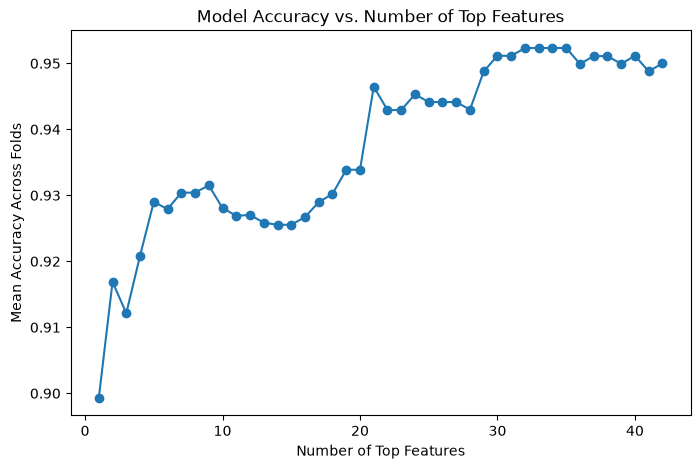

In [ ]:
# Keep the features in the folds from the forward selection
all_selected_features = [
    feat for fold in selected_features_per_fold for feat in fold
]
feature_counts = Counter(all_selected_features)

# 2. Set up arrays for tracking metrics
x_top_n_features = []  # X-axis: Number of top features used
y_mean_accuracy = []  # Y-axis: Average accuracy achieved

# Define max number of features to evaluate (up to total unique features)
max_features = min(50, len(feature_counts))

# 3. Loop through feature set sizes
for k in range(1, max_features + 1):
  # Get top k features
  top_k_features = [feat for feat, _ in feature_counts.most_common(k) if feat in X.columns]
  X_consensus = X[top_k_features]

  fold_scores = []

  for train_idx, test_idx in logo.split(X_consensus, y, groups=groups):
    X_train, X_test = X_consensus.iloc[train_idx], X_consensus.iloc[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    #Yes this could be a function and I call a model, this is a lazy work around
    #ada_final = RandomForestClassifier(n_estimators=100, random_state=42)
    #ada_final = LGBMClassifier(
    #    n_estimators=200, learning_rate=0.03, num_leaves=6,
    #    min_child_samples=30, colsample_bytree=0.5,
    #    subsample=0.8, subsample_freq=1, reg_lambda=5,
    #    random_state=42, verbose=-1
    #)
    ada_final = SVC(kernel='rbf', C=1.0, gamma='auto', random_state=42)

    


    #ada_final = AdaBoostClassifier(n_estimators=50, learning_rate=1)
    ada_final.fit(X_train, y_train)
    preds = ada_final.predict(X_test)

    fold_scores.append(accuracy_score(y_test, preds))

  # Store results
  x_top_n_features.append(k)
  y_mean_accuracy.append(np.mean(fold_scores))

#Plot the accuracy against the number of features used
plt.figure(figsize=(8, 5))
plt.plot(x_top_n_features, y_mean_accuracy, marker="o")
plt.xlabel("Number of Top Features")
plt.ylabel("Mean Accuracy Across Folds")
plt.title("Model Accuracy vs. Number of Top Features")
plt.show()

Model with optimal features

In [ ]:
# Aggregate feature counts across all folds
all_selected_features = [
    feat for fold in selected_features_per_fold for feat in fold
]
feature_counts = Counter(all_selected_features)

# Select the top N top features from the previous graphs determination
# Can probably call the list and select max accuracy and features to reduce hard-coding
N_TOP_FEATURES = 32
best_averaged_set = [
    feat for feat, _ in feature_counts.most_common(N_TOP_FEATURES)
]

print("=" * 50)
print(f"BEST AVERAGED FEATURE SET (Top {N_TOP_FEATURES} across all folds):")
for feat, count in feature_counts.most_common(N_TOP_FEATURES):
  print(
      f"  - {feat}: selected in {count}/{len(scores)} folds"
      f" ({count/len(scores)*100:.1f}%)"
  )
print("=" * 50)

# 3. Re-evaluate model across all subjects using ONLY the on average best feature set
X_consensus = X[best_averaged_set]

consensus_scores = []
#ada_final = RandomForestClassifier(n_estimators=100, random_state=42)
ada_final = SVC(kernel='rbf', C=1.0, gamma='auto', random_state=42)

#ada_final = SVC(kernel='rbf', C=1.0, random_state=42)

#ada_final = AdaBoostClassifier(random_state=42)

for train_idx, test_idx in logo.split(X_consensus, y, groups=groups):
  X_train, X_test = X_consensus.iloc[train_idx], X_consensus.iloc[test_idx]
  y_train, y_test = y[train_idx], y[test_idx]

  ada_final.fit(X_train, y_train)
  preds = ada_final.predict(X_test)

  consensus_scores.append(accuracy_score(y_test, preds))

# 4. Final Results Output
print("\nEVALUATION WITH AVERAGED FEATURE SET:")
print(f"Accuracy for each subject: {consensus_scores}")
print(
    "Average Accuracy across all unseen subjects:"
    f" {np.mean(consensus_scores):.4f}"
)

BEST AVERAGED FEATURE SET (Top 32 across all folds):
  - phasic_peak_count_rk: selected in 8/15 folds (53.3%)
  - phasic_mean_rk: selected in 7/15 folds (46.7%)
  - tonic_mean_slope_bl: selected in 6/15 folds (40.0%)
  - tonic_mean_bl: selected in 4/15 folds (26.7%)
  - eda_max_bl: selected in 4/15 folds (26.7%)
  - tonic_min_rk: selected in 3/15 folds (20.0%)
  - eda_sampen_rk: selected in 2/15 folds (13.3%)
  - eda_mean_slope_rk: selected in 2/15 folds (13.3%)
  - phasic_std_rise_time_bl: selected in 2/15 folds (13.3%)
  - tonic_min_bl: selected in 2/15 folds (13.3%)
  - tonic_mean_slope_rk: selected in 2/15 folds (13.3%)
  - eda_skew_bl: selected in 2/15 folds (13.3%)
  - phasic_std_rk: selected in 2/15 folds (13.3%)
  - phasic_mean_bl: selected in 1/15 folds (6.7%)
  - eda_median_rk: selected in 1/15 folds (6.7%)
  - eda_min_rk: selected in 1/15 folds (6.7%)
  - tonic_skew_bl: selected in 1/15 folds (6.7%)
  - phasic_range_rk: selected in 1/15 folds (6.7%)
  - phasic_sampen_rk: sel

LGBM with some regularization added

In [121]:
model = LGBMClassifier(
    n_estimators=200, learning_rate=0.03, num_leaves=6,
    min_child_samples=30, colsample_bytree=0.5,
    subsample=0.8, subsample_freq=1, reg_lambda=5,
    random_state=42, verbose=-1
)
# Generate out-of-fold predictions
y_pred = cross_val_predict(model, X, y, groups=groups, cv=logo)

# Display Precision, Recall, F1-Score, and Accuracy
print("\nClassification Report:")
print(classification_report(y, y_pred))


Classification Report:
              precision    recall  f1-score   support

         1.0       0.91      0.97      0.94       548
         2.0       0.95      0.82      0.88       297

    accuracy                           0.92       845
   macro avg       0.93      0.90      0.91       845
weighted avg       0.92      0.92      0.92       845

